# 6주차 실습: 이진 트리 구조 설계 및 순회 — 학생용

## 실습 목표 및 규약
TreeNode/BinaryTree 설계, 재귀 DFS 3종, 반복 전위, 큐 기반 BFS, 높이·노드·리프 수를 구현한다.
- Python 3.8+ / Jupyter 또는 Colab. 위에서 아래 순서로 실행한다.
- 루트 깊이 0, 리프 높이 0, 빈 트리 높이 -1: **간선 수 기준**.
- 일반 이진 트리는 BST가 아니다. 중위 순회가 항상 정렬되는 것은 아니다.
- 이 실습의 구조는 사이클·공유 자식 없는 트리라고 가정한다.
- `BinaryTree(None)`은 빈 트리를 뜻한다. None 값을 가진 루트는 `tree.root = TreeNode(None)`으로 생성한다.


In [1]:
from collections import deque
print("실습 환경 준비 완료")

실습 환경 준비 완료


## Step 1. TreeNode
데이터와 왼쪽/오른쪽 자식 참조를 저장합니다.

In [2]:
class TreeNode:
    def __init__(self, data):
        self.data = data
        self.left = None
        self.right = None

    def __repr__(self):
        return f"TreeNode({self.data!r})"

## Step 2. BinaryTree
전위 NLR / 중위 LNR / 후위 LRN. 재귀는 None에서 종료. 반복 전위는 오른쪽 먼저 push.

In [3]:
class BinaryTree:
    def __init__(self, root_data=None):
        # root_data가 None이면 빈 트리
        self.root = None if root_data is None else TreeNode(root_data)

    def preorder(self):
        result = []
        def visit(node):
            if node is None:
                return
            result.append(node.data)   # N
            visit(node.left)           # L
            visit(node.right)          # R
        visit(self.root)
        return result

    def inorder(self):
        result = []
        def visit(node):
            if node is None:
                return
            visit(node.left)           # L
            result.append(node.data)   # N
            visit(node.right)          # R
        visit(self.root)
        return result

    def postorder(self):
        result = []
        def visit(node):
            if node is None:
                return
            visit(node.left)           # L
            visit(node.right)          # R
            result.append(node.data)   # N
        visit(self.root)
        return result

    def preorder_iterative(self):
        result = []
        if self.root is None:
            return result
        stack = [self.root]
        while stack:
            node = stack.pop()
            result.append(node.data)
            # 왼쪽이 먼저 나오도록 오른쪽을 먼저 push
            if node.right is not None:
                stack.append(node.right)
            if node.left is not None:
                stack.append(node.left)
        return result

    def levelorder(self):
        result = []
        if self.root is None:
            return result
        queue = deque([self.root])
        while queue:
            node = queue.popleft()
            result.append(node.data)
            if node.left is not None:
                queue.append(node.left)
            if node.right is not None:
                queue.append(node.right)
        return result

    def height(self):
        def h(node):
            if node is None:
                return -1
            return 1 + max(h(node.left), h(node.right))
        return h(self.root)

    def count_nodes(self):
        def count(node):
            if node is None:
                return 0
            return 1 + count(node.left) + count(node.right)
        return count(self.root)

    def count_leaves(self):
        def leaves(node):
            if node is None:
                return 0
            if node.left is None and node.right is None:
                return 1
            return leaves(node.left) + leaves(node.right)
        return leaves(self.root)

## Step 3. 예시 트리
```text
      A
    /   \
   B     C
  / \     \
 D   E     F
```

In [4]:
tree = BinaryTree("A")
tree.root.left = TreeNode("B")
tree.root.right = TreeNode("C")
tree.root.left.left = TreeNode("D")
tree.root.left.right = TreeNode("E")
tree.root.right.right = TreeNode("F")

## Step 4. 결과 및 경계 사례 검증

In [5]:
expected = {
    "preorder": ["A", "B", "D", "E", "C", "F"],
    "inorder": ["D", "B", "E", "A", "C", "F"],
    "postorder": ["D", "E", "B", "F", "C", "A"],
    "levelorder": ["A", "B", "C", "D", "E", "F"]
}
for method, answer in expected.items():
    actual = getattr(tree, method)()
    print(method, actual)
    assert actual == answer
assert tree.preorder_iterative() == tree.preorder()
assert (tree.height(), tree.count_nodes(), tree.count_leaves()) == (2, 6, 3)
print("예시 트리 테스트 통과")


preorder ['A', 'B', 'D', 'E', 'C', 'F']
inorder ['D', 'B', 'E', 'A', 'C', 'F']
postorder ['D', 'E', 'B', 'F', 'C', 'A']
levelorder ['A', 'B', 'C', 'D', 'E', 'F']
예시 트리 테스트 통과


In [6]:
for t, sequence, height, leaves in [
    (BinaryTree(), [], -1, 0),
    (BinaryTree("X"), ["X"], 0, 1),
]:
    for method in ["preorder", "inorder", "postorder", "levelorder", "preorder_iterative"]:
        assert getattr(t, method)() == sequence
    assert (t.height(), t.count_nodes(), t.count_leaves()) == (height, len(sequence), leaves)

skew = BinaryTree(1)
skew.root.right = TreeNode(2)
skew.root.right.right = TreeNode(3)
assert skew.preorder() == skew.inorder() == skew.levelorder() == [1, 2, 3]
assert skew.postorder() == [3, 2, 1]
assert skew.preorder_iterative() == [1, 2, 3]
assert (skew.height(), skew.count_nodes(), skew.count_leaves()) == (2, 3, 1)
print("빈 트리 / 단일 노드 / 편향 트리 테스트 통과")


빈 트리 / 단일 노드 / 편향 트리 테스트 통과


## Step 5. VisuAlgo 시각화 및 검증
[VisuAlgo BST](https://visualgo.net/en/bst)는 **BST 시각화**이며 임의의 A~F 이진 트리를 직접 만드는 도구라고 가정하지 않습니다.
1. BST 모드에서 빈 트리에 **4, 2, 6, 1, 3, 7** 순서로 삽입합니다(자동 균형 모드와 구별).
2. A→4, B→2, C→6, D→1, E→3, F→7 대응으로 위 예시와 구조를 비교합니다.
3. 화면에서 제공되는 순회 기능은 애니메이션으로 검증하고, 미지원 순회는 그림 위에 방문 번호를 적어 검증합니다.
4. 아래 코드 결과와 수동 trace를 비교하고 캡처와 설명을 기록하세요. **BST 삽입은 다음 주 내용이며 이번에는 구조 관찰만 합니다.**


In [7]:
numeric = BinaryTree(4)
numeric.root.left = TreeNode(2)
numeric.root.right = TreeNode(6)
numeric.root.left.left = TreeNode(1)
numeric.root.left.right = TreeNode(3)
numeric.root.right.right = TreeNode(7)
assert numeric.preorder() == [4, 2, 1, 3, 6, 7]
assert numeric.inorder() == [1, 2, 3, 4, 6, 7]
assert numeric.postorder() == [1, 3, 2, 7, 6, 4]
assert numeric.levelorder() == [4, 2, 6, 1, 3, 7]
for method in ["preorder", "inorder", "postorder", "levelorder"]:
    print(method, getattr(numeric, method)())


preorder [4, 2, 1, 3, 6, 7]
inorder [1, 2, 3, 4, 6, 7]
postorder [1, 3, 2, 7, 6, 4]
levelorder [4, 2, 6, 1, 3, 7]


### VisuAlgo 시각화 결과 및 방문 순서 검증

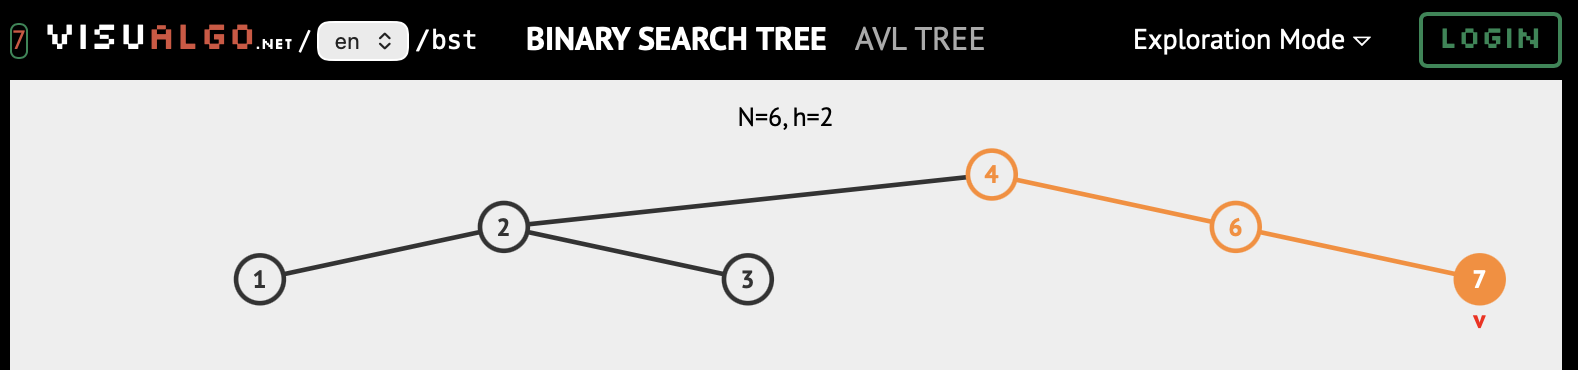

VisuAlgo BST(Exploration Mode)에서 빈 트리에 **4, 2, 6, 1, 3, 7** 순서로 삽입한 결과입니다. 화면 상단의 `N=6, h=2`는 위 코드의 `count_nodes() == 6`, `height() == 2`(간선 기준)와 일치합니다.

**구조 대응** (A→4, B→2, C→6, D→1, E→3, F→7)
- 4의 왼쪽 자식 2, 오른쪽 자식 6 → A의 자식 B, C
- 2의 자식 1, 3 → B의 자식 D, E
- 6은 오른쪽 자식 7만 가짐 → C는 오른쪽 자식 F만 가짐
- 리프: 1, 3, 7 → `count_leaves() == 3`

캡처의 주황색 경로(4 → 6 → 7)는 마지막 값 7을 삽입할 때 루트에서 오른쪽으로 내려간 탐색 경로입니다.

**방문 순서 수동 trace (그림 위 방문 번호)**

|순회|규칙|방문 순서|코드 결과|
|---|---|---|---|
|전위|N→L→R|4(①) 2(②) 1(③) 3(④) 6(⑤) 7(⑥)|`[4, 2, 1, 3, 6, 7]`|
|중위|L→N→R|1(①) 2(②) 3(③) 4(④) 6(⑤) 7(⑥)|`[1, 2, 3, 4, 6, 7]`|
|후위|L→R→N|1(①) 3(②) 2(③) 7(④) 6(⑤) 4(⑥)|`[1, 3, 2, 7, 6, 4]`|
|레벨|깊이 0→1→2, 왼쪽→오른쪽|4(①) 2(②) 6(③) 1(④) 3(⑤) 7(⑥)|`[4, 2, 6, 1, 3, 7]`|

수동 trace와 코드 출력이 네 가지 순회 모두 일치합니다. 이 트리는 BST 규칙으로 만들어졌기 때문에 중위 순회가 정렬된 순서로 나오지만, 일반 이진 트리(A~F 예시)에서는 중위 순회 결과 `D B E A C F`가 정렬 순서와 무관합니다.

## 복잡도 분석
n=노드 수, h=간선 기준 높이, w=최대 레벨 너비.

|연산|시간|보조 공간(출력 제외)|
|---|---|---|
|재귀 DFS 3종 / 반복 전위|O(n)|O(h+1)|
|큐 기반 레벨 순회|O(n)|O(w)|
|높이·노드 수·리프 수|O(n)|O(h+1)|
|완전 트리 구성|O(n)|O(n) 큐 + O(n) 생성 노드|

순회 반환 리스트는 별도 O(n) 공간입니다. 균형 트리는 h=O(log n), 편향 트리는 h=O(n). 깊은 편향 트리의 재귀는 Python 재귀 깊이 제한에 걸릴 수 있습니다. BFS도 깊이별 수집으로 재귀 구현 가능하지만 큐 기반 반복이 자연스럽습니다.


## 제출 과제: 이진 트리 순회 프로그램
1. build_complete_tree(values)를 구현하고 네 가지 순회 결과 출력.
2. 빈/단일/완전/편향 트리 테스트 및 시간·공간 복잡도 설명.
3. 시각화 캡처와 방문 순서 검증 설명 첨부.
4. 개인 GitHub의 Week6 폴더에 노트북/설명 저장. 계획서대로 주당 최소 2회 커밋, 과제 폼에 GitHub 링크 제출.

주의: 아래 TODO를 구현하기 전 학생용 테스트 실패는 정상입니다. 미구현 셀은 무한 반복 대신 NotImplementedError로 즉시 중단합니다.


In [8]:
def build_complete_tree(values):
    tree = BinaryTree()
    if not values:
        return tree
    # None도 실제 데이터 값이므로 루트를 직접 생성
    tree.root = TreeNode(values[0])
    queue = deque([tree.root])
    i = 1
    while i < len(values):
        parent = queue.popleft()
        parent.left = TreeNode(values[i])
        queue.append(parent.left)
        i += 1
        if i < len(values):
            parent.right = TreeNode(values[i])
            queue.append(parent.right)
            i += 1
    return tree

In [9]:
complete = build_complete_tree([1, 2, 3, 4, 5, 6, 7])
assert complete.preorder() == [1, 2, 4, 5, 3, 6, 7]
assert complete.inorder() == [4, 2, 5, 1, 6, 3, 7]
assert complete.postorder() == [4, 5, 2, 6, 7, 3, 1]
assert complete.levelorder() == [1, 2, 3, 4, 5, 6, 7]
assert complete.preorder_iterative() == complete.preorder()
assert build_complete_tree([]).height() == -1
assert build_complete_tree([9]).levelorder() == [9]
assert build_complete_tree([1, 2, 3, 4]).levelorder() == [1, 2, 3, 4]
assert build_complete_tree([None, 2]).levelorder() == [None, 2]
for method in ["preorder", "inorder", "postorder", "levelorder"]:
    print(method, getattr(complete, method)())
print("과제 테스트 통과")


preorder [1, 2, 4, 5, 3, 6, 7]
inorder [4, 2, 5, 1, 6, 3, 7]
postorder [4, 5, 2, 6, 7, 3, 1]
levelorder [1, 2, 3, 4, 5, 6, 7]
과제 테스트 통과


### 과제 2. 빈 / 단일 / 완전 / 편향 트리 테스트

In [ ]:
def build_skewed_tree(values, direction="right"):
    """한쪽 방향으로만 자식을 연결한 편향 트리를 만든다."""
    tree = BinaryTree()
    if not values:
        return tree
    tree.root = TreeNode(values[0])
    node = tree.root
    for value in values[1:]:
        child = TreeNode(value)
        if direction == "right":
            node.right = child
        else:
            node.left = child
        node = child
    return tree


def report(name, t):
    print(f"[{name}] height={t.height()}, nodes={t.count_nodes()}, leaves={t.count_leaves()}")
    for method in ["preorder", "inorder", "postorder", "levelorder"]:
        print(f"  {method:<10} {getattr(t, method)()}")
    assert t.preorder_iterative() == t.preorder()


cases = [
    # (이름, 트리, 전위, 중위, 후위, 레벨, 높이, 노드 수, 리프 수)
    ("빈 트리", build_complete_tree([]),
     [], [], [], [], -1, 0, 0),
    ("단일 노드", build_complete_tree([10]),
     [10], [10], [10], [10], 0, 1, 1),
    ("완전 트리", build_complete_tree([1, 2, 3, 4, 5, 6]),
     [1, 2, 4, 5, 3, 6], [4, 2, 5, 1, 6, 3], [4, 5, 2, 6, 3, 1], [1, 2, 3, 4, 5, 6], 2, 6, 3),
    ("오른쪽 편향 트리", build_skewed_tree([1, 2, 3, 4], "right"),
     [1, 2, 3, 4], [1, 2, 3, 4], [4, 3, 2, 1], [1, 2, 3, 4], 3, 4, 1),
    ("왼쪽 편향 트리", build_skewed_tree([1, 2, 3, 4], "left"),
     [1, 2, 3, 4], [4, 3, 2, 1], [4, 3, 2, 1], [1, 2, 3, 4], 3, 4, 1),
]

for name, t, pre, ino, post, level, h, n, leaves in cases:
    report(name, t)
    assert t.preorder() == pre
    assert t.inorder() == ino
    assert t.postorder() == post
    assert t.levelorder() == level
    assert (t.height(), t.count_nodes(), t.count_leaves()) == (h, n, leaves)
print("빈 / 단일 / 완전 / 편향 트리 테스트 통과")

### 시간·공간 복잡도 설명

n = 노드 수, h = 간선 기준 높이, w = 최대 레벨 너비

|연산|시간|보조 공간|이유|
|---|---|---|---|
|`build_complete_tree`|O(n)|O(n)|값마다 노드를 1번 생성하고 큐에 1번 넣고 1번 꺼냄. 큐에는 최대 약 n/2개의 부모 후보가 있고, 생성된 노드 자체도 O(n)|
|전위·중위·후위 (재귀)|O(n)|O(h)|각 노드를 정확히 1번 방문. 호출 스택 깊이가 루트→리프 경로 길이(h+1)와 같음|
|반복 전위 (스택)|O(n)|O(h)|각 노드를 1번 push, 1번 pop. 스택에는 경로상 노드의 형제들만 남아 O(h) 수준|
|레벨 순회 (큐)|O(n)|O(w)|각 노드를 1번 enqueue, 1번 dequeue. 큐에는 많아야 인접한 두 레벨의 노드만 들어 있음|
|`height` / `count_nodes` / `count_leaves`|O(n)|O(h)|모든 노드를 후위 방식으로 1번씩 방문하는 재귀|

순회 결과 리스트는 출력용으로 별도 O(n) 공간을 씁니다.

**트리 모양에 따른 차이**
- **빈 트리**: 바로 종료되므로 O(1). 높이 -1, 노드 0, 리프 0.
- **단일 노드**: O(1). 높이 0, 노드 1, 리프 1. 네 가지 순회 결과가 모두 `[10]`으로 같음.
- **완전 트리**: h = ⌊log₂ n⌋이므로 DFS 공간은 **O(log n)**. 대신 마지막 레벨이 가장 넓어 w ≈ n/2, 레벨 순회 큐 공간은 **O(n)**.
- **편향 트리**: h = n − 1이므로 DFS 공간이 **O(n)**까지 커짐(연결 리스트와 같은 모양). 대신 레벨마다 노드가 1개(w = 1)라 레벨 순회 큐는 **O(1)**. n이 매우 크면 재귀 구현은 Python 재귀 한도(기본 약 1000)에 걸릴 수 있어 반복 구현이 더 안전함.
- 오른쪽 편향 트리는 전위 = 중위 = 레벨 순회 결과가 같고, 왼쪽 편향 트리는 중위 = 후위 = 전위의 역순이라는 것을 위 테스트에서 확인할 수 있음.

어떤 모양이든 **시간은 항상 O(n)**(모든 노드를 1번씩 방문)이고, **공간은 DFS는 높이, BFS는 너비**에 비례한다는 점이 핵심입니다.